# CC2017 – Deep Learning · Proyecto Final
## 02 · CNN entrenada desde cero

Se entrena una red convolucional propia sobre imágenes de 48×48. Esta es la línea base contra la que se compara el modelo preentrenado del notebook 03.

## Preparación · Librerías, reproducibilidad y dispositivo

In [1]:
import sys, random, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)

# FAST_DEV_RUN=True recorre pocos lotes por época para comprobar que todo corre; sus checkpoints llevan prefijo dev_.
FAST_DEV_RUN = False
MAX_BATCHES = 5 if FAST_DEV_RUN else None
PREFIX = 'dev_' if FAST_DEV_RUN else ''
NUM_WORKERS = 2
print('Dispositivo:', device, '| FAST_DEV_RUN:', FAST_DEV_RUN)

Dispositivo: cpu | FAST_DEV_RUN: False


## 1. Datos

In [2]:
from src.data import download_gtsrb, load_tables, split_train_val, GTSRBDataset, get_transforms, CLASS_NAMES, NUM_CLASSES

DATA_ROOT = download_gtsrb()
train_full, test_df = load_tables(DATA_ROOT)
train_df, val_df = split_train_val(train_full, val_size=0.15, seed=SEED)
print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')

c:\Users\mdax8\Desktop\UVG\8 Semestre\Deep Learning\Proyecto Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 33,299 | Val: 5,910 | Test: 12,630


In [3]:
IMG_SIZE = 48
batch_size = 128

train_ds = GTSRBDataset(train_df, DATA_ROOT, get_transforms(IMG_SIZE, augment=True))
val_ds = GTSRBDataset(val_df, DATA_ROOT, get_transforms(IMG_SIZE))
train_loader = DataLoader(train_ds, batch_size, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_ds, batch_size, num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)

## 2. Arquitectura
Tres bloques `[Conv-BN-ReLU]×2 → MaxPool → Dropout2d` con 32, 64 y 128 filtros. Luego, pooling global promedio y un clasificador denso con dropout. El pooling global evita una capa densa grande y reduce parámetros.

In [4]:
from src.models import TrafficCNN, count_params
cnn = TrafficCNN().to(device)
total, trainable = count_params(cnn)
print(cnn)
print(f'Parámetros: {total:,} (entrenables: {trainable:,})')

TrafficCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-

## 3. Entrenamiento
Adam con lr 1e-3, `ReduceLROnPlateau` y early stopping sobre la pérdida de validación. Se guardan los pesos de la mejor época. Si el checkpoint ya existe se carga en lugar de entrenar.

In [5]:
epochs = 30
lr = 1e-3
optimizer = torch.optim.Adam(cnn.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)

from src.train import fit
t0 = time.time()
hist_cnn = fit(cnn, train_loader, val_loader, optimizer, device, epochs=2 if FAST_DEV_RUN else epochs,
               scheduler=scheduler, patience=5, ckpt_path=OUT / f'{PREFIX}cnn_scratch.pt', max_batches=MAX_BATCHES)
print(f'Tiempo total: {time.time() - t0:.0f}s')

Época 01 | train loss 2.7313 acc 0.2229 | val loss 1.8370 acc 0.4036 | lr 1.0e-03 | 272s
Época 02 | train loss 1.6060 acc 0.4662 | val loss 1.1751 acc 0.5902 | lr 1.0e-03 | 95s
Época 03 | train loss 0.8681 acc 0.7160 | val loss 0.4962 acc 0.8313 | lr 1.0e-03 | 88s
Época 04 | train loss 0.4087 acc 0.8711 | val loss 0.3612 acc 0.8975 | lr 1.0e-03 | 93s
Época 05 | train loss 0.2270 acc 0.9307 | val loss 0.0984 acc 0.9690 | lr 1.0e-03 | 94s
Época 06 | train loss 0.1668 acc 0.9496 | val loss 0.0886 acc 0.9753 | lr 1.0e-03 | 80s
Época 07 | train loss 0.1201 acc 0.9639 | val loss 0.0881 acc 0.9702 | lr 1.0e-03 | 95s
Época 08 | train loss 0.1112 acc 0.9678 | val loss 0.0820 acc 0.9717 | lr 1.0e-03 | 100s
Época 09 | train loss 0.0834 acc 0.9764 | val loss 0.0404 acc 0.9871 | lr 1.0e-03 | 87s
Época 10 | train loss 0.0739 acc 0.9783 | val loss 0.0315 acc 0.9910 | lr 1.0e-03 | 99s
Época 11 | train loss 0.0635 acc 0.9811 | val loss 0.0452 acc 0.9882 | lr 1.0e-03 | 96s
Época 12 | train loss 0.0593 a

## 4. Curvas de entrenamiento

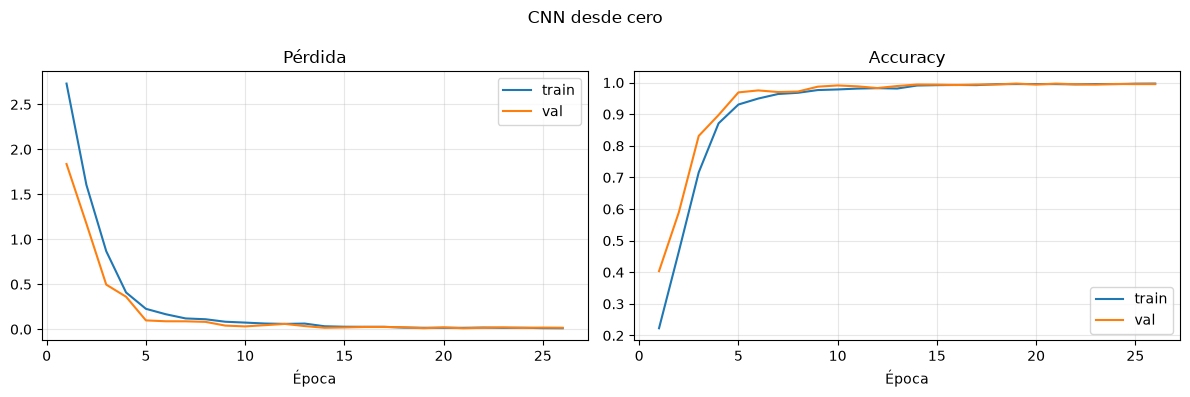

Mejor época: 21 | val loss 0.0110 | val acc 0.9968


In [6]:
def plot_history(h, title):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(h['train_loss']) + 1)
    axs[0].plot(ep, h['train_loss'], label='train'); axs[0].plot(ep, h['val_loss'], label='val'); axs[0].set(title='Pérdida', xlabel='Época')
    axs[1].plot(ep, h['train_acc'], label='train'); axs[1].plot(ep, h['val_acc'], label='val'); axs[1].set(title='Accuracy', xlabel='Época')
    for ax in axs: ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); return fig

plot_history(hist_cnn, 'CNN desde cero').savefig(OUT / 'curvas_cnn.png', dpi=120); plt.show()
best = int(np.argmin(hist_cnn['val_loss']))
print(f"Mejor época: {best + 1} | val loss {hist_cnn['val_loss'][best]:.4f} | val acc {hist_cnn['val_acc'][best]:.4f}")

## 5. Métricas en validación

In [7]:
from src.metrics import predict, summary_metrics
y_val, p_val, _ = predict(cnn, val_loader, device, MAX_BATCHES)
pd.DataFrame([summary_metrics(y_val, p_val, 'CNN desde cero (val)')]).round(4)

,modelo,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,CNN desde cero (val),0.9968,0.9967,0.9929,0.9945,0.9968,0.9968,0.9967


**Interpretación.** La pérdida disminuye con rapidez durante las primeras diez épocas y luego se estabiliza. La mejor pérdida de validación se obtuvo en la época 21, con accuracy de 0.9968 y F1 macro de 0.9945. No se observa una brecha sostenida que indique sobreajuste severo; las oscilaciones finales motivan el early stopping en la época 26. La accuracy de entrenamiento puede ser ligeramente menor que la de validación porque durante entrenamiento se aplican aumento de datos y dropout.